# ICS554 Prosit 1 — Section B: an n-gram language model for Twi

Code: https://github.com/Elise-Oyi/NLP-Prosit-1

Steps 1–9 build add-k smoothed n-gram models; Steps 10–12 add Kneser-Ney smoothing; Step 13 is the one-time test-set evaluation. Figures are saved to `figures/`.

In [1]:
# Task 1 (Section B) — Step 1: load the Twi sentences
import os, shutil

# Running locally (or the file was uploaded to Colab): read it from this folder.
# Otherwise connect Google Drive and read it from there.
if os.path.exists("twi_sentences.txt"):
    folder = "."
else:
    # If Drive isn't connected, clear anything left in its spot so it can connect
    if not os.path.ismount("/content/drive"):
        shutil.rmtree("/content/drive", ignore_errors=True)
    from google.colab import drive              # a pop-up will ask for permission
    drive.mount('/content/drive')
    folder = "/content/drive/MyDrive/Ashesi/ICS554_Prosit1"

# Open the file and read every line into a list called all_text
# Each line is one Twi sentence; strip() removes the invisible line-break at the end
with open(folder + "/twi_sentences.txt", encoding="utf-8") as f:
    all_text = [line.strip() for line in f if line.strip()]

# Show how many sentences we have, and the first three
print("Sentences loaded:", len(all_text))
for sentence in all_text[:3]:
    print(sentence)

Sentences loaded: 79655
Ɛyɛ me nwanwa sɛ yɛbɛtumi aka saa nsɛm yi.
Mma ɔkraman no ntu nkɔto kwaeɛ no so efisɛ ɔbɛhwerɛ ne nkwa nso.
Yɛnhwɛ mma yɛn future no nni nnyinasoɔ a ɛyɛ den na mmom yɛn nna adwuma a ɛbɛma yɛn society no ayɛ baako.


In [2]:
# Task 1 (Section B) — Step 2: look at the data

# Split every sentence into words and collect them
words = [w for s in all_text for w in s.split()]

print("Sentences:        ", len(all_text))
print("Total words:      ", len(words))
print("Different words:  ", len(set(words)))
print("Duplicate sentences:", len(all_text) - len(set(all_text)))

Sentences:         79655
Total words:       1129653
Different words:   41492
Duplicate sentences: 89


In [3]:
# Task 1 (Section B) — Step 3: clean the data
import string

def clean(sentence):
    sentence = sentence.lower()                  # Ɛyɛ -> ɛyɛ
    for p in string.punctuation:                 # remove . , ? ! etc.
        sentence = sentence.replace(p, "")
    return " ".join(sentence.split())            # tidy extra spaces

cleaned = [clean(s) for s in all_text]
cleaned = [s for s in cleaned if s]              # drop empty lines
cleaned = list(dict.fromkeys(cleaned))           # drop sentences that are identical after cleaning

words = [w for s in cleaned for w in s.split()]
print("Sentences after cleaning:", len(cleaned))
print("Different words:         ", len(set(words)))
print(cleaned[:2])

Sentences after cleaning: 79550
Different words:          31056
['ɛyɛ me nwanwa sɛ yɛbɛtumi aka saa nsɛm yi', 'mma ɔkraman no ntu nkɔto kwaeɛ no so efisɛ ɔbɛhwerɛ ne nkwa nso']


In [4]:
# Chart style used by every figure below (figures are also saved to figures/ for the report)
import matplotlib.pyplot as plt
os.makedirs("figures", exist_ok=True)

BLUE, ORANGE = "#2a78d6", "#eb6834"          # add-k = blue, Kneser-Ney = orange
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e1e0d9"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": MUTED, "text.color": INK,
    "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
})

Words seen only once: 16123 of 31056 (52%)


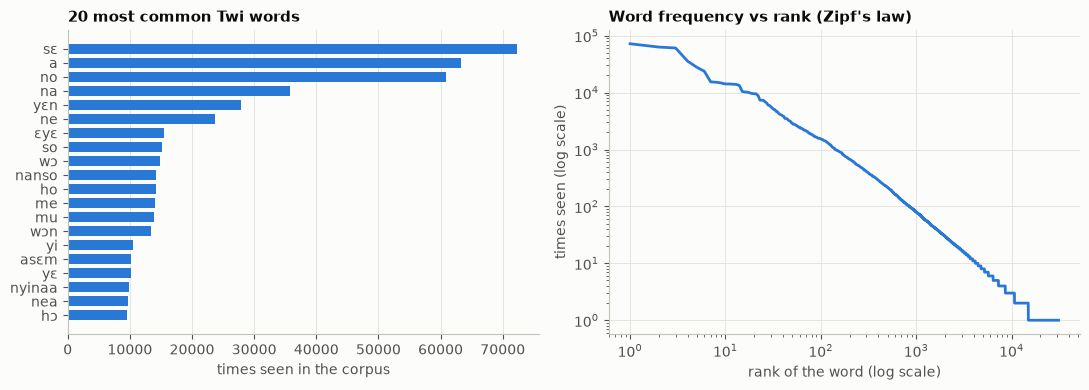

In [5]:
# Task 1 (Section B) — Step 3b: what the data looks like (word frequencies)
from collections import Counter
freq = Counter(w for s in cleaned for w in s.split())
top = freq.most_common(20)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))

ax1.barh([w for w, _ in top][::-1], [c for _, c in top][::-1], color=BLUE, height=0.7)
ax1.set_title("20 most common Twi words")
ax1.set_xlabel("times seen in the corpus")
ax1.grid(axis="y", visible=False)

# Zipf's law: the 2nd most common word appears about half as often as the 1st, and so on.
# On a log-log plot that is a straight line - most words are rare.
counts_sorted = sorted(freq.values(), reverse=True)
ax2.loglog(range(1, len(counts_sorted) + 1), counts_sorted, color=BLUE, linewidth=2)
ax2.set_title("Word frequency vs rank (Zipf's law)")
ax2.set_xlabel("rank of the word (log scale)")
ax2.set_ylabel("times seen (log scale)")

once = sum(1 for c in freq.values() if c == 1)
print(f"Words seen only once: {once} of {len(freq)} ({once/len(freq):.0%})")
plt.tight_layout()
plt.savefig("figures/word_frequencies.png", dpi=150)
plt.show()

In [6]:
# Task 1 (Section B) — Step 4: split into train, dev and test
import random

random.seed(42)                    # same shuffle every run
shuffled = cleaned[:]
random.shuffle(shuffled)           # mix the order

n = len(shuffled)
train = shuffled[: int(n * 0.8)]
dev   = shuffled[int(n * 0.8) : int(n * 0.9)]
test  = shuffled[int(n * 0.9) :]

print("Train:", len(train))
print("Dev:  ", len(dev))
print("Test: ", len(test))

Train: 63640
Dev:   7955
Test:  7955


In [7]:
# Task 1 (Section B) — Step 5: count words and word pairs (training)
from collections import Counter

unigrams = Counter()     # single words
bigrams = Counter()      # pairs of words

for sentence in train:                       # training data only
    tokens = ["<s>"] + sentence.split() + ["</s>"]
    for i in range(len(tokens)):
        unigrams[tokens[i]] += 1
        if i > 0:
            bigrams[(tokens[i-1], tokens[i])] += 1

V = len(unigrams)                            # vocabulary size
print("Different words in training:", V)
print("Different word pairs:       ", len(bigrams))

Different words in training: 27659
Different word pairs:        196491


In [8]:
# Task 1 (Section B) — Step 6: predict the next word

def predict_next(word, top=5):
    # every pair that starts with this word, and its count
    followers = {w2: c for (w1, w2), c in bigrams.items() if w1 == word}
    total = unigrams[word]                      # how often the word appeared
    best = sorted(followers.items(), key=lambda x: x[1], reverse=True)[:top]
    for w2, c in best:
        print(f"{word} → {w2}   ({c}/{total} = {c/total:.1%})")

predict_next("me")

me → ne   (799/11228 = 7.1%)
me → werɛ   (564/11228 = 5.0%)
me → ya   (516/11228 = 4.6%)
me → ho   (477/11228 = 4.2%)
me → sɛ   (414/11228 = 3.7%)


In [9]:
predict_next("me")
predict_next("wo")
predict_next("sika")

me → ne   (799/11228 = 7.1%)
me → werɛ   (564/11228 = 5.0%)
me → ya   (516/11228 = 4.6%)
me → ho   (477/11228 = 4.2%)
me → sɛ   (414/11228 = 3.7%)
wo → ho   (592/4010 = 14.8%)
wo → nsa   (212/4010 = 5.3%)
wo → </s>   (155/4010 = 3.9%)
wo → ne   (119/4010 = 3.0%)
wo → nni   (91/4010 = 2.3%)
sika → a   (691/3210 = 21.5%)
sika → no   (555/3210 = 17.3%)
sika → ne   (213/3210 = 6.6%)
sika → </s>   (144/3210 = 4.5%)
sika → nko   (128/3210 = 4.0%)


In [10]:
predict_next("werɛ")

werɛ → how   (267/756 = 35.3%)
werɛ → fi   (104/756 = 13.8%)
werɛ → mfi   (62/756 = 8.2%)
werɛ → aho   (51/756 = 6.7%)
werɛ → remfi   (33/756 = 4.4%)


In [11]:
# Task 1 (Section B) — Step 7: fix the "never seen it" problem (smoothing)

def prob(prev, word):
    # plain count ÷ count — unseen pairs get 0
    return bigrams[(prev, word)] / unigrams[prev]

def prob_k(prev, word, k):
    # add k to every count, so nothing is ever 0
    return (bigrams[(prev, word)] + k) / (unigrams[prev] + k * V)

print("No smoothing:  ", prob("me", "nintendo"))
print("With k = 0.01: ", prob_k("me", "nintendo", 0.01))

No smoothing:   0.0
With k = 0.01:  8.692182859189246e-07


In [12]:
# Task 1 (Section B) — Step 8: score the model (perplexity) and choose k
import math

def perplexity(sentences, k):
    total_log, count = 0.0, 0
    for s in sentences:
        tokens = ["<s>"] + s.split() + ["</s>"]
        for i in range(1, len(tokens)):
            total_log += math.log(prob_k(tokens[i-1], tokens[i], k))  # add up surprise
            count += 1
    return math.exp(-total_log / count)          # turn average surprise into a score

k_results = {}
for k in [0.0001, 0.001, 0.002, 0.005, 0.01, 0.1, 1.0]:
    k_results[k] = perplexity(dev, k)
    print("k =", k, "→ dev perplexity:", round(k_results[k], 2))

k = 0.0001 → dev perplexity: 209.74


k = 0.001 → dev perplexity: 176.35


k = 0.002 → dev perplexity: 173.44


k = 0.005 → dev perplexity: 176.23


k = 0.01 → dev perplexity: 184.85


k = 0.1 → dev perplexity: 291.35


k = 1.0 → dev perplexity: 793.17


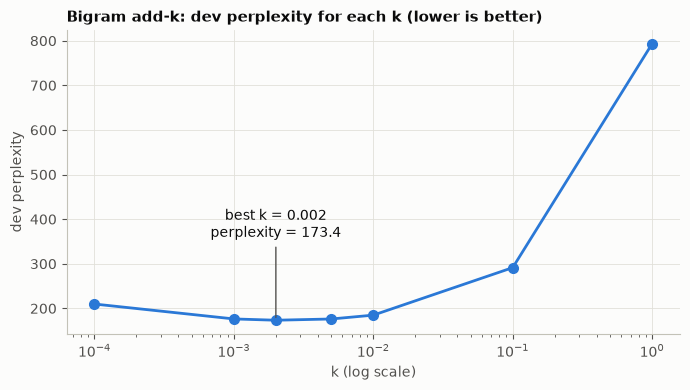

In [13]:
# Task 1 (Section B) — Step 8b: picture of the k search
ks_tried = sorted(k_results)
best_k = min(k_results, key=k_results.get)

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(ks_tried, [k_results[k] for k in ks_tried], color=BLUE, linewidth=2, marker="o", markersize=7)
ax.set_xscale("log")
ax.set_title("Bigram add-k: dev perplexity for each k (lower is better)")
ax.set_xlabel("k (log scale)")
ax.set_ylabel("dev perplexity")
ax.annotate(f"best k = {best_k}\nperplexity = {k_results[best_k]:.1f}",
            (best_k, k_results[best_k]), xytext=(0, 60), textcoords="offset points",
            ha="center", color=INK, arrowprops=dict(arrowstyle="-", color=MUTED))
plt.tight_layout()
plt.savefig("figures/addk_k_search.png", dpi=150)
plt.show()

In [14]:
# Task 1 (Section B) — Step 9: compare with unigram and trigram

N = sum(unigrams.values())                       # total words in training

# Unigram: ignores the previous word
def unigram_perplexity(sentences, k):
    total_log, count = 0.0, 0
    for s in sentences:
        for w in s.split() + ["</s>"]:
            total_log += math.log((unigrams[w] + k) / (N + k * V))
            count += 1
    return math.exp(-total_log / count)

# Trigram: count triples, looking two words back (training data only)
trigrams, pair_context = Counter(), Counter()
for s in train:
    tokens = ["<s>", "<s>"] + s.split() + ["</s>"]
    for i in range(2, len(tokens)):
        trigrams[(tokens[i-2], tokens[i-1], tokens[i])] += 1
        pair_context[(tokens[i-2], tokens[i-1])] += 1

def trigram_perplexity(sentences, k):
    total_log, count = 0.0, 0
    for s in sentences:
        tokens = ["<s>", "<s>"] + s.split() + ["</s>"]
        for i in range(2, len(tokens)):
            p = (trigrams[(tokens[i-2], tokens[i-1], tokens[i])] + k) / \
                (pair_context[(tokens[i-2], tokens[i-1])] + k * V)
            total_log += math.log(p)
            count += 1
    return math.exp(-total_log / count)

# Try several k for each model, keep the best (dev only)
ks = [0.0001, 0.0005, 0.001, 0.002, 0.01, 0.1, 1.0]
best_uni = min((unigram_perplexity(dev, k), k) for k in ks)
best_tri = min((trigram_perplexity(dev, k), k) for k in ks)

print(f"Unigram: {best_uni[0]:.2f}  (k = {best_uni[1]})")
print(f"Bigram:  {perplexity(dev, 0.002):.2f}  (k = 0.002)")
print(f"Trigram: {best_tri[0]:.2f}  (k = {best_tri[1]})")

Unigram: 421.10  (k = 1.0)


Bigram:  173.44  (k = 0.002)
Trigram: 492.45  (k = 0.001)


In [15]:
# Task 1 (Section B) — Step 9b: try 4-grams and 5-grams

def build_ngrams(n):
    grams, context = Counter(), Counter()
    for s in train:                                         # training data only
        tokens = ["<s>"] * (n - 1) + s.split() + ["</s>"]
        for i in range(n - 1, len(tokens)):
            grams[tuple(tokens[i-n+1 : i+1])] += 1          # the n words together
            context[tuple(tokens[i-n+1 : i])] += 1          # the words before the last
    return grams, context

def ngram_perplexity(sentences, n, grams, context, k):
    total_log, count = 0.0, 0
    for s in sentences:
        tokens = ["<s>"] * (n - 1) + s.split() + ["</s>"]
        for i in range(n - 1, len(tokens)):
            p = (grams[tuple(tokens[i-n+1 : i+1])] + k) / \
                (context[tuple(tokens[i-n+1 : i])] + k * V)
            total_log += math.log(p)
            count += 1
    return math.exp(-total_log / count)

addk_best = {1: best_uni, 2: (perplexity(dev, 0.002), 0.002), 3: best_tri}
for n in [4, 5]:
    grams, context = build_ngrams(n)
    best = min((ngram_perplexity(dev, n, grams, context, k), k) for k in ks)
    addk_best[n] = best
    print(f"{n}-gram: {best[0]:.2f}  (k = {best[1]})   different sequences: {len(grams)}")

4-gram: 1896.54  (k = 0.0005)   different sequences: 661696


5-gram: 4396.53  (k = 0.0005)   different sequences: 753372


In [16]:
# Task 1 (Section B) — Step 10: Kneser-Ney smoothing
#
# Add-k gives every unseen word the same small share. Kneser-Ney is smarter in two ways:
#  1. Discounting: take a fixed amount d (e.g. 0.75) off every count we did see,
#     and hand that saved probability to a shorter context (back off).
#  2. Continuation counts: the shorter context does not ask "how often is this word seen?"
#     but "after how many DIFFERENT words has this word been seen?". A word that only
#     ever follows one particular word is not a good guess in a new context.
#
#  P(w | context) = max(count(context, w) - d, 0) / count(context)
#                 + d * (number of different words after context) / count(context) * P(w | shorter context)
#
# The shortest context finally mixes with 1/V, so even a word never seen in training gets a small share.

def build_kn(n):
    counts = {n: build_ngrams(n)[0]}               # top order: ordinary counts
    for m in range(n - 1, 0, -1):                  # lower orders: continuation counts
        cont = Counter()
        for gram in counts[m + 1]:
            cont[gram[1:]] += 1                    # one more different word seen before gram[1:]
        counts[m] = cont

    totals, followers = {}, {}                     # per context: total count, different next words
    for m, grams in counts.items():
        tot, fol = Counter(), Counter()
        for gram, c in grams.items():
            tot[gram[:-1]] += c
            fol[gram[:-1]] += 1
        totals[m], followers[m] = tot, fol
    return counts, totals, followers

def kn_prob(model, word, context, d):
    counts, totals, followers = model
    m = len(context) + 1
    shorter = 1 / V if m == 1 else kn_prob(model, word, context[1:], d)
    total = totals[m].get(context, 0)
    if total == 0:                                 # context never seen: use the shorter one
        return shorter
    c = counts[m].get(context + (word,), 0)
    return max(c - d, 0) / total + d * followers[m][context] / total * shorter

def kn_perplexity(sentences, n, model, d):
    total_log, count = 0.0, 0
    for s in sentences:
        tokens = ["<s>"] * (n - 1) + s.split() + ["</s>"]
        for i in range(n - 1, len(tokens)):
            total_log += math.log(kn_prob(model, tokens[i], tuple(tokens[i-n+1 : i]), d))
            count += 1
    return math.exp(-total_log / count)

# Sanity check: for any context, the probabilities of all words must add up to 1
kn3 = build_kn(3)
for context in [("<s>", "<s>"), ("me", "werɛ"), ("sika", "no")]:
    print(context, "→ sum over all words =", round(sum(kn_prob(kn3, w, context, 0.75) for w in unigrams), 6))

('<s>', '<s>') → sum over all words = 1.0
('me', 'werɛ')

 → sum over all words = 1.0
('sika', 'no') → sum over all words = 1.0


In [17]:
# Task 1 (Section B) — Step 11: choose d and n for Kneser-Ney (dev only)
ds = [0.5, 0.6, 0.7, 0.75, 0.8, 0.85, 0.9, 0.95]   # d must stay below 1
kn_models, kn_best, kn_d_results = {}, {}, {}

for n in [1, 2, 3, 4, 5]:
    kn_models[n] = build_kn(n)
    kn_d_results[n] = {d: kn_perplexity(dev, n, kn_models[n], d) for d in ds}
    best_d = min(kn_d_results[n], key=kn_d_results[n].get)
    kn_best[n] = (kn_d_results[n][best_d], best_d)

print("n   add-k (best k)            Kneser-Ney (best d)")
for n in [1, 2, 3, 4, 5]:
    print(f"{n}   {addk_best[n][0]:8.2f}  (k = {addk_best[n][1]:<6})   {kn_best[n][0]:8.2f}  (d = {kn_best[n][1]})")

best_n = min(kn_best, key=lambda n: kn_best[n][0])
best_d = kn_best[best_n][1]
print(f"\nBest Kneser-Ney model: {best_n}-gram with d = {best_d}")

n   add-k (best k)            Kneser-Ney (best d)
1     421.10  (k = 1.0   )     391.24  (d = 0.95)
2     173.44  (k = 0.002 )     111.71  (d = 0.8)
3     492.45  (k = 0.001 )      84.38  (d = 0.85)
4    1896.54  (k = 0.0005)      80.55  (d = 0.9)
5    4396.53  (k = 0.0005)      80.46  (d = 0.9)

Best Kneser-Ney model: 5-gram with d = 0.9


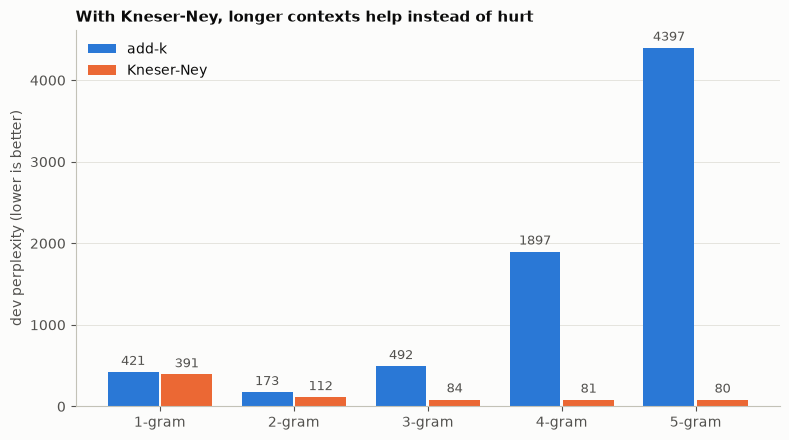

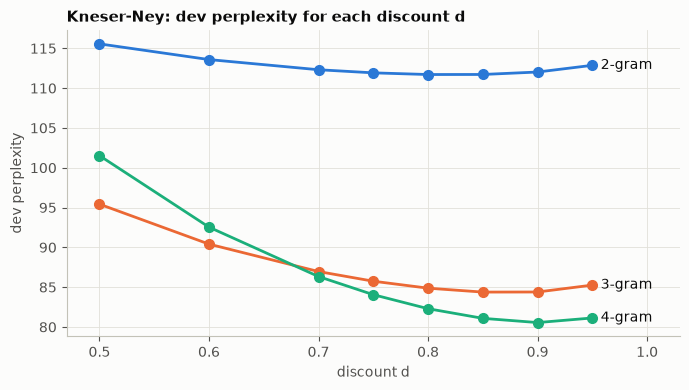

In [18]:
# Task 1 (Section B) — Step 11b: add-k vs Kneser-Ney for every n
import numpy as np

orders = [1, 2, 3, 4, 5]
x = np.arange(len(orders))
w = 0.38

fig, ax = plt.subplots(figsize=(8, 4.5))
b1 = ax.bar(x - w/2 - 0.01, [addk_best[n][0] for n in orders], w, color=BLUE, label="add-k")
b2 = ax.bar(x + w/2 + 0.01, [kn_best[n][0] for n in orders], w, color=ORANGE, label="Kneser-Ney")
for bars in (b1, b2):
    ax.bar_label(bars, fmt="%.0f", padding=3, color=MUTED, fontsize=9)
ax.set_xticks(x, [f"{n}-gram" for n in orders])
ax.set_ylabel("dev perplexity (lower is better)")
ax.set_title("With Kneser-Ney, longer contexts help instead of hurt")
ax.legend(frameon=False)
ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.savefig("figures/addk_vs_kneser_ney.png", dpi=150)
plt.show()

fig, ax = plt.subplots(figsize=(7, 4))
for n, color in [(2, BLUE), (3, ORANGE), (4, "#1baf7a")]:
    ax.plot(ds, [kn_d_results[n][d] for d in ds], color=color, linewidth=2, marker="o", markersize=7)
    ax.annotate(f"{n}-gram", (ds[-1], kn_d_results[n][ds[-1]]), xytext=(6, 0),
                textcoords="offset points", va="center", color=INK)
ax.set_title("Kneser-Ney: dev perplexity for each discount d")
ax.set_xlabel("discount d")
ax.set_ylabel("dev perplexity")
ax.set_xlim(ds[0] - 0.03, ds[-1] + 0.08)
plt.tight_layout()
plt.savefig("figures/kneser_ney_d_search.png", dpi=150)
plt.show()

In [19]:
# Task 1 (Section B) — Step 12: is it learning? Predict and write Twi with the best model

def kn_predict_next(context_words, top=5):
    context = tuple((["<s>"] * best_n + context_words)[-(best_n - 1):])
    scores = {w: kn_prob(kn_models[best_n], w, context, best_d) for w in unigrams if w != "<s>"}
    best = sorted(scores.items(), key=lambda x: x[1], reverse=True)[:top]
    print(" ".join(context_words), "→", ",  ".join(f"{w} ({p:.1%})" for w, p in best))

kn_predict_next(["me", "werɛ"])
kn_predict_next(["me", "ho"])
kn_predict_next(["sika", "no"])

def generate(max_words=20):
    vocab = [w for w in unigrams if w != "<s>"]
    tokens = ["<s>"] * (best_n - 1)
    for _ in range(max_words):
        context = tuple(tokens[-(best_n - 1):])
        weights = [kn_prob(kn_models[best_n], w, context, best_d) for w in vocab]
        word = random.choices(vocab, weights)[0]       # pick a word in proportion to its probability
        if word == "</s>":
            break
        tokens.append(word)
    return " ".join(tokens[best_n - 1:])

random.seed(1)
print("\nSentences written by the model:")
for _ in range(5):
    print(" -", generate())

me werɛ → how (51.6%),  fi (10.8%),  remfi (5.9%),  mfi (5.9%),  aho (5.2%)


me ho → yɛ (54.5%),  nni (7.4%),  abere (3.0%),  </s> (2.9%),  sɛ (2.1%)


sika no → yɛ (22.7%),  wɔ (6.2%),  ho (5.5%),  ne (4.3%),  ba (4.0%)

Sentences written by the model:


 - nanso ɔkwan no a ɛnde ɛsɛ sɛ yɛhwehwɛ kwan a yɛbɛfa so anya nanso nkurɔfoɔ pii adwene abue nhwehwɛmu ne


 - sɛ wosɛe woahwere wo kwan


 - sɛ ɛnyɛ saa a ɛhe na ɔman no bɛkɔ so ahwɛ yɛn hub no wɔnyɛɛ recession no mu nneɛma kɔ


 - wɔreko obiara repere ne ho sɛ yɛbɛma asase no mu na wɔde krataa no kyerɛ sɛ nkwa yɛ hu


 - saa anansesɛm yi kyerɛ yɛn sɛ sɛ yɛpɛ dan mu


In [20]:
# Task 1 (Section B) — Step 13: final exam on the test set (run once)

print("Add-k bigram (k = 0.002)")
print("  Dev perplexity: ", round(perplexity(dev, 0.002), 2))
print("  Test perplexity:", round(perplexity(test, 0.002), 2))

print(f"Kneser-Ney {best_n}-gram (d = {best_d})")
print("  Dev perplexity: ", round(kn_perplexity(dev, best_n, kn_models[best_n], best_d), 2))
print("  Test perplexity:", round(kn_perplexity(test, best_n, kn_models[best_n], best_d), 2))

Add-k bigram (k = 0.002)
  Dev perplexity:  173.44


  Test perplexity: 175.27
Kneser-Ney 5-gram (d = 0.9)


  Dev perplexity:  80.46


  Test perplexity: 80.14
